# 1.Generamos todas las funciones a utilizar en el modelo

In [265]:
import pandas as pd
import re
from textwrap import fill
pd.set_option('display.max_rows', None)      # muestra TODAS las filas
pd.set_option('display.max_columns', None)   # …y TODAS las columnas si hubiera truncación horizontal
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns


from scipy.stats.mstats import winsorize
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from scipy.stats import chi2_contingency
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.preprocessing import MinMaxScaler



In [266]:
def explorar_dataset(df: pd.DataFrame,
                     target: str = None,
                     max_pairplot: int = 10,
                     bins_hist: int = 20):
    """Explora rápidamente un DataFrame: tipos, nulos, describe, histogramas,
       boxplots y scatter/pairplots.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a explorar.
    target : str, opcional
        Columna objetivo; si se pasa, los scatter se hacen contra ella.
    max_pairplot : int
        Máximo de columnas que se incluyen en el pairplot para no saturar.
    bins_hist : int
        Número de bins de los histogramas.
    """

    # 0. Encabezado bonito
    print("="*80)
    print("EXPLORACIÓN BÁSICA DEL DATASET".center(80))
    print("="*80, "\n")

    # 1. Tipos de dato
    print("1️⃣  TIPOS DE DATOS\n" + "-"*80)
    display(df.dtypes.value_counts().to_frame("Nº columnas"))
    display(df.dtypes.sort_index())
    print()

    # 2. Valores nulos
    print("2️⃣  VALORES NULOS POR COLUMNA\n" + "-"*80)
    nulos = df.isna().sum()
    display(nulos[nulos > 0].sort_values(ascending=False).to_frame("n_nulos"))
    if nulos.sum() == 0:
        print("✅  No se encontraron valores nulos.\n")
    print()

    # 3. Estadísticas descriptivas
    print("3️⃣  ESTADÍSTICAS DESCRIPTIVAS\n" + "-"*80)
    display(df.describe(include='all').T)
    print()

    # 4. Columnas numéricas
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if num_cols:
        # 4.1 Histogramas
        print("4️⃣  HISTOGRAMAS DE VARIABLES NUMÉRICAS\n" + "-"*80)
        n = len(num_cols)
        cols = 3
        rows = int(np.ceil(n / cols))
        plt.figure(figsize=(cols*5, rows*3))
        for i, col in enumerate(num_cols, 1):
            plt.subplot(rows, cols, i)
            df[col].plot.hist(bins=bins_hist, alpha=0.7)
            plt.title(col)
            plt.tight_layout()
        plt.show()

        # 4.2 Boxplots
        print("5️⃣  DIAGRAMAS DE CAJA\n" + "-"*80)
        for col in num_cols:
            plt.figure(figsize=(6, 2.5))
            sns.boxplot(x=df[col])
            plt.title(f'Boxplot · {col}')
            plt.show()

        # 4.3 Scatter / Pairplot
        print("6️⃣  GRÁFICOS DE DISPERSIÓN\n" + "-"*80)
        if target and target in df.columns:
            # Scatter cada numérica vs. objetivo
            for col in num_cols:
                if col == target:
                    continue
                plt.figure(figsize=(4, 3))
                sns.scatterplot(x=df[col], y=df[target], s=10, alpha=0.6)
                plt.title(f'{col} vs {target}')
                plt.tight_layout()
                plt.show()
        else:
            # Pairplot limitado
            subset = num_cols[:max_pairplot]
            print(f"Pairplot de las primeras {len(subset)} numéricas "
                  f"(max_pairplot={max_pairplot})")
            sns.pairplot(df[subset], diag_kind='hist', plot_kws={'alpha': 0.4, 's': 15})
            plt.show()
    else:
        print("ℹ️  El DataFrame no contiene columnas numéricas.")

    print("\nExploración terminada ✔️")


In [267]:
import matplotlib.pyplot as plt
import seaborn as sns

def analizar_variables_categoricas(df, umbral_rareza=0.01):
    """
    Analiza variables categóricas sin modificar el DataFrame original.
    - Muestra frecuencia absoluta y relativa
    - Identifica categorías raras según umbral_rareza
    - Para el gráfico, agrupa las categorías raras en 'otro',
      pero SOLO en una copia temporal (no cambia df)
    """

    cat_cols = df.select_dtypes(include='object').columns

    for col in cat_cols:
        print(f"\n=== Análisis para '{col}' ===")

        # Frecuencia en los datos originales
        print("\nFrecuencia absoluta (original):")
        print(df[col].value_counts())

        print("\nFrecuencia relativa (%) (original):")
        print(df[col].value_counts(normalize=True) * 100)

        # --- Agrupación de clases raras SOLO PARA LA GRÁFICA ---
        freqs = df[col].value_counts(normalize=True)
        rare_labels = freqs[freqs < umbral_rareza].index

        # Serie temporal para graficar
        col_plot = df[col].copy()
        col_plot = col_plot.replace(rare_labels, "otro")

        # Gráfico de barras con clases raras agrupadas
        plt.figure(figsize=(8, 4))
        orden = col_plot.value_counts().index
        sns.countplot(x=col_plot, order=orden)
        plt.title(f"Distribución de '{col}' (clases raras agrupadas como 'otro')")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


In [268]:
def limpiar_dataset(df):

#    Limpieza de datos:
#    - Reemplaza 'valor_que_falta' por NaN
#    - Elimina espacios extras en nombres de columnas y valores de tipo string
#    - Muestra resumen de valores faltantes

    # Eliminar espacios en los nombres de columnas
    df.columns = df.columns.str.strip()

    # Reemplazar valores especiales por NaN
    df.replace("valor_que_falta", np.nan, inplace=True)

    # Eliminar espacios extra en strings
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

    # Detectar duplicados
    duplicados = df.duplicated().sum()
    if duplicados > 0:
        df.drop_duplicates(inplace=True)

    # Reporte de valores faltantes
    faltantes = df.isnull().sum()
    faltantes_porcentaje = df.isnull().sum()/len(df)*100
    print("\n\n Valores faltantes por variable independiente:")
    print(faltantes[faltantes > 0])
    print("\n\n Porcentaje de valores faltantes por variable independiente:")
    print(faltantes_porcentaje[faltantes_porcentaje > 0])

    return df


In [269]:
import numpy as np
import pandas as pd

def limpiar_vacios(df, binarias):
    """
    Limpieza del dataset:
    - Convierte 'si'/'no' en variables binarias (1/0)
    - Imputa categóricas con moda
    - Imputa numéricas con mediana (si la columna era entero, se convierte a entero)
    """

    df = df.copy()

    # ---------------------------
    # 1. Normalizar nombres y strings
    # ---------------------------
    df.columns = df.columns.str.strip()

    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip().str.lower()

    # ---------------------------
    # 2. Imputar categóricas con moda
    # ---------------------------
    cat_cols = df.select_dtypes(include='object').columns

    for col in cat_cols:
        if df[col].isnull().sum() > 0:
            moda = df[col].mode(dropna=True)[0]
            df[col] = df[col].fillna(moda)

    # ---------------------------
    # 3. Variables binarias si/no → 1/0
    # ---------------------------
    for col in binarias:
        if col in df.columns:
            df[col] = df[col].map({"si": 1, "no": 0})
            df[col] = df[col].fillna(0).astype(int)  # fuerza entero
        else:
            print(f"⚠ Advertencia: columna binaria '{col}' no encontrada en DF")

    # ---------------------------
    # 4. Imputar numéricas con mediana
    #    Si la columna era int64, imputamos como int
    # ---------------------------
    num_cols = df.select_dtypes(include=np.number).columns

    for col in num_cols:
        if df[col].isnull().sum() > 0:
            mediana = df[col].median()

            # Si era entero, convertir la mediana a entero
            if pd.api.types.is_integer_dtype(df[col]):
                mediana = int(mediana)
                df[col] = df[col].fillna(mediana).astype(int)
            else:
                df[col] = df[col].fillna(mediana)

    print("Variables binarias convertidas a número: ", binarias)
    print("Imputación completada sin valores nulos restantes.")

    return df


In [270]:
def detectar_outliers_iqr_df(df, umbral_outliers=1):

    outliers_dict = {}
    resumen = []

    columnas = df.columns

    for col in columnas:
        Q1 = df[col].quantile(0.20)
        Q3 = df[col].quantile(0.80)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        mask_outliers = (df[col] < lower_bound) | (df[col] > upper_bound)
        n_outliers = mask_outliers.sum()
        outliers = df[mask_outliers]

        outliers_dict[col] = outliers
        resumen.append({
            'Columna': col,
            'Outliers detectados': n_outliers,
            'Porcentaje': round(mask_outliers.mean() * 100, 2)
        })

        if  mask_outliers.mean() * 100 >= umbral_outliers:
          plt.figure(figsize=(6, 1.5))
          sns.boxplot(x=df[col])
          plt.title(f'Boxplot (con outliers): {col}')
          plt.grid(True, axis='x', linestyle='--', linewidth=0.5)
          plt.tight_layout()
          plt.show()

    resumen_df = pd.DataFrame(resumen).sort_values(by='Outliers detectados', ascending=False)
    return outliers_dict, resumen_df



In [271]:
def limpiar_inmuebles(df):
    """
    Limpia y transforma el DataFrame de inmuebles para análisis/ML.
    - Convierte columnas de texto a numéricas
    - Separa la dirección en referencia / distrito / ciudad
    """
    df = df.copy()  # no modificar el original

    # --- 1) precio ---
    df["precio"] = (
        df["precio"]
          .astype(str)
          .str.replace(".", "", regex=False)
          .str.replace(",", "", regex=False)
    )
    df["precio"] = pd.to_numeric(df["precio"], errors="coerce").fillna(0)

    # --- 2) áreas ---
    for col in ["area_total", "area_cubierta"]:
        df[col] = (
            df[col]
              .astype(str)
              .str.extract(r"(\d+)")
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # --- 3) baños completos ---
    df["banos"] = (
        df["banos"]
          .astype(str)
          .str.extract(r"(\d+)")
    )
    df["banos"] = pd.to_numeric(df["banos"], errors="coerce").fillna(0).astype(int)

    # --- 4) medios baños (vacío = 0) ---
    df["medios_banos"] = (
        df["medios_banos"]
          .astype(str)
          .str.extract(r"(\d+)")
    )
    df["medios_banos"] = (
        pd.to_numeric(df["medios_banos"], errors="coerce")
          .fillna(0)
          .astype(int)
    )

    # --- 5) cochera (vacío = 0) ---
    df["cochera"] = (
        df["cochera"]
          .astype(str)
          .str.extract(r"(\d+)")
    )
    df["cochera"] = (
        pd.to_numeric(df["cochera"], errors="coerce")
          .fillna(0)
          .astype(int)
    )

    # --- 6) dormitorios ---
    df["dormitorio"] = (
        df["dormitorio"]
          .astype(str)
          .str.extract(r"(\d+)")
    )
    df["dormitorio"] = (
        pd.to_numeric(df["dormitorio"], errors="coerce")
          .fillna(0)
          .astype(int)
    )

    # --- 7) antigüedad ---
    def limpiar_antiguedad(x):
        x = str(x).lower()
        if "estrenar" in x:
            return 0
        m = re.search(r"(\d+)", x)
        return int(m.group(1)) if m else 0

    df["antiguedad"] = df["antiguedad"].apply(limpiar_antiguedad).astype(int)

    return df


In [272]:
import re

def extraer_region_distrito(texto, regiones_peru, regiones_distritos):
    if pd.isna(texto):
        return pd.Series([None, None, None])

    original = texto
    texto = texto.lower()

    # ---------------------------
    # 1. Buscar REGIÓN
    # ---------------------------
    region_encontrada = None
    for region in regiones_peru:
        if region.lower() in texto:
            region_encontrada = region
            break

    # ---------------------------
    # 2. Buscar DISTRITO (dependiendo de la región)
    # ---------------------------
    distrito_encontrado = None

    if region_encontrada and region_encontrada in regiones_distritos:
        for distrito in regiones_distritos[region_encontrada]:
            if distrito.lower() in texto:
                distrito_encontrado = distrito
                break

    # ---------------------------
    # 3. Extraer "otros"
    # ---------------------------
    otros = original

    if region_encontrada:
        otros = re.sub(region_encontrada, "", otros, flags=re.IGNORECASE)
    if distrito_encontrado:
        otros = re.sub(distrito_encontrado, "", otros, flags=re.IGNORECASE)

    # Quitar espacios dobles
    otros = re.sub(r"\s+", " ", otros).strip()
    if otros == "":
        otros = None

    return pd.Series([region_encontrada, distrito_encontrado, otros])


In [273]:
def outliers_por_columna(df, columna, q1=0.20, q3=0.80):
    Q1 = df[columna].quantile(q1)
    Q3 = df[columna].quantile(q3)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[columna] < lower) | (df[columna] > upper)]
    return outliers, lower, upper


In [274]:
import unicodedata

def normalizar(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).upper()
    # Quitar tildes
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    # Quitar espacios dobles
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()


In [275]:
def extraer_dep_prov_dist(direccion: str):
    """
    A partir de una dirección tipo:
    'Av. Pachacutec  al 2300,  Villa María del Triunfo, Lima'

    devuelve:
    departamento, provincia, distrito, otros
    siguiendo la lógica:
    - dividir por comas
    - último → dep, si no prov, si no dist
    - si tengo dep, penúltimo → prov (o dist si no es prov)
    - si tengo dep+prov, antepenúltimo → dist
    """

    if pd.isna(direccion):
        return pd.Series([None, None, None, None])

    # 1) separar por comas
    partes_raw = [p.strip() for p in str(direccion).split(",") if p.strip()]
    partes_norm = [normalizar(p) for p in partes_raw]
    n = len(partes_norm)

    if n == 0:
        return pd.Series([None, None, None, None])

    departamento = None
    provincia = None
    distrito = None

    idx_dep = idx_prov = idx_dist = None  # índices de las partes usadas

    # ---------------------------
    # 1) Intentar con ÚLTIMO = DEPARTAMENTO
    # ---------------------------
    candidato_last = partes_norm[-1]
    mask_dep = ubigeo["DEPARTAMENTO_N"] == candidato_last

    if mask_dep.any():
        # Encontró departamento
        fila_dep = ubigeo[mask_dep].iloc[0]
        departamento = fila_dep["DEPARTAMENTO"]
        idx_dep = n - 1

        # ---- Penúltimo → intentar como PROVINCIA dentro de ese dep ----
        if n >= 2:
            candidato_pen = partes_norm[-2]
            dept_rows = ubigeo[mask_dep]

            mask_prov = dept_rows["PROVINCIA_N"] == candidato_pen
            if mask_prov.any():
                # Penúltimo es provincia
                fila_prov = dept_rows[mask_prov].iloc[0]
                provincia = fila_prov["PROVINCIA"]
                idx_prov = n - 2

                # ---- Antepenúltimo → DISTRITO dentro de dep+prov ----
                if n >= 3:
                    candidato_ante = partes_norm[-3]
                    prov_rows = dept_rows[mask_prov]
                    mask_dist = prov_rows["DISTRITO_N"] == candidato_ante
                    if mask_dist.any():
                        fila_dist = prov_rows[mask_dist].iloc[0]
                        distrito = fila_dist["DISTRITO"]
                        idx_dist = n - 3

            else:
                # Penúltimo NO es provincia → probarlo como DISTRITO dentro del dep
                mask_dist2 = dept_rows["DISTRITO_N"] == candidato_pen
                if mask_dist2.any():
                    fila_dist = dept_rows[mask_dist2].iloc[0]
                    distrito = fila_dist["DISTRITO"]
                    provincia = fila_dist["PROVINCIA"]
                    idx_dist = n - 2
                    # En este caso provincia la tomamos de la fila del distrito

    else:
        # ---------------------------
        # 2) ÚLTIMO NO ES DEP → Intentar como PROVINCIA
        # ---------------------------
        mask_prov_global = ubigeo["PROVINCIA_N"] == candidato_last
        if mask_prov_global.any():
            fila_prov = ubigeo[mask_prov_global].iloc[0]
            provincia = fila_prov["PROVINCIA"]
            departamento = fila_prov["DEPARTAMENTO"]
            idx_prov = n - 1

            # Penúltimo → DISTRITO dentro de esa provincia
            if n >= 2:
                candidato_pen = partes_norm[-2]
                prov_rows = ubigeo[mask_prov_global]
                mask_dist = prov_rows["DISTRITO_N"] == candidato_pen
                if mask_dist.any():
                    fila_dist = prov_rows[mask_dist].iloc[0]
                    distrito = fila_dist["DISTRITO"]
                    idx_dist = n - 2

        else:
            # ---------------------------
            # 3) ÚLTIMO NO ES PROV → Intentar como DISTRITO
            # ---------------------------
            mask_dist_global = ubigeo["DISTRITO_N"] == candidato_last
            if mask_dist_global.any():
                candidatos = ubigeo[mask_dist_global]

                # Priorizar el que tenga DEPARTAMENTO_N == 'LIMA'
                prefer_lima = candidatos[candidatos["DEPARTAMENTO_N"] == "LIMA"]

                if len(prefer_lima) > 0:
                    fila_dist = prefer_lima.iloc[0]
                else:
                    fila_dist = candidatos.iloc[0]

                distrito = fila_dist["DISTRITO"]
                provincia = fila_dist["PROVINCIA"]
                departamento = fila_dist["DEPARTAMENTO"]
                idx_dist = n - 1
            else:
                departamento = provincia = distrito = None


    # ---------------------------
    # 4) Construir "otros"
    # ---------------------------
    indices_usados = {idx for idx in [idx_dep, idx_prov, idx_dist] if idx is not None}
    otros_partes = [
        partes_raw[i] for i in range(n) if i not in indices_usados
    ]
    otros = ", ".join(otros_partes).strip() if otros_partes else None

    return pd.Series([departamento, provincia, distrito, otros])


# 2.Análisis y descripción del set de datos

In [276]:
from pathlib import Path
import pandas as pd

# 1. Ruta de la carpeta donde están tus CSV
BASE_DIR = Path.cwd()
print("ruta:")
print(BASE_DIR)
DATA_URL = BASE_DIR / "Scrapping"
carpeta = Path(BASE_DIR)

# 2. Buscar todos los archivos que empiezan con "inmuebles_" y terminan en ".csv"
archivos_csv = sorted(carpeta.glob("inmuebles_*.csv"))

print("Archivos encontrados:")
for f in archivos_csv:
    print(" -", f.name)

# 3. Leer cada CSV y guardarlo en una lista
dataframes = []

for archivo in archivos_csv:
    print(f"Leyendo: {archivo.name}")

    # Ajusta 'sep' o 'encoding' si tus archivos lo necesitan
    df = pd.read_csv(archivo, sep=';', engine='python')  # ej: pd.read_csv(archivo, sep=";", encoding="latin-1")

    # (Opcional) agregar una columna con el nombre del archivo de origen
    df["origen_archivo"] = archivo.name

    dataframes.append(df)

# 4. Unir todos los DataFrames en uno solo
df_total = pd.concat(dataframes, ignore_index=True)

print("Tamaño final de la tabla:", df_total.shape)

# 5. Guardar el resultado en un nuevo CSV
salida = carpeta / "inmuebles_vf.csv"
df_total.to_csv(salida, index=False)
print(f"Archivo combinado guardado en: {salida}")


ruta:
C:\Users\alexa\OneDrive\Documentos\GitHub\proyecto_urbania
Archivos encontrados:
 - inmuebles_maria.csv
 - inmuebles_michael.csv
 - inmuebles_prueba.csv
 - inmuebles_prueba_3.csv
 - inmuebles_prueba_4.csv
Leyendo: inmuebles_maria.csv
Leyendo: inmuebles_michael.csv
Leyendo: inmuebles_prueba.csv
Leyendo: inmuebles_prueba_3.csv
Leyendo: inmuebles_prueba_4.csv
Tamaño final de la tabla: (1673, 16)
Archivo combinado guardado en: C:\Users\alexa\OneDrive\Documentos\GitHub\proyecto_urbania\inmuebles_vf.csv


In [277]:
df = df_total
display(df.head())

,tipo_contrato,tipo_vivienda,precio,distrito,direccion,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,descripcion,url,fecha_extraccion,origen_archivo
0,Alquiler,Departamento,"1,200",Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",110 m² tot.,110 m² cub.,3 baños,NaN,NaN,3 dorm.,5 años,Alquiler Barato Departamento en Los Olivos\nAl...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,inmuebles_maria.csv
1,Alquiler,Departamento,"1,300",Ate Vitarte,"De la Unión 303, 27 De Abril, Ate Vitarte",60 m² tot.,60 m² cub.,1 baño,NaN,NaN,1 dorm.,5 años,Minidepartamento de un Dorm. en Tercer Piso / ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,inmuebles_maria.csv
2,Alquiler,Departamento,"2,650",Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate Vitarte",160 m² tot.,160 m² cub.,1 baño,1 medio baño,NaN,3 dorm.,5 años,"Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,inmuebles_maria.csv
3,Alquiler,Departamento,"3,850",Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...",144 m² tot.,144 m² cub.,2 baños,NaN,1 estac.,3 dorm.,20 años,"Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,inmuebles_maria.csv
4,Alquiler,Departamento,"2,850",Cayma,"Cayma Baja, Alto Gloria, Cayma",125 m² tot.,110 m² cub.,2 baños,1 medio baño,1 estac.,2 dorm.,8 años,Departamento Alto de La Gloria - Cayma\nLindo ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,inmuebles_maria.csv


In [278]:
df.shape[0]
df = df.drop(columns=[
'origen_archivo'])

## 2.1 Analizamos los datos numéricos

In [279]:
explorar_dataset(df,target='precio', max_pairplot=12)

                         EXPLORACIÓN BÁSICA DEL DATASET                         

1️⃣  TIPOS DE DATOS
--------------------------------------------------------------------------------


,Nº columnas
object,15


antiguedad          object
area_cubierta       object
area_total          object
banos               object
cochera             object
descripcion         object
direccion           object
distrito            object
dormitorio          object
fecha_extraccion    object
medios_banos        object
precio              object
tipo_contrato       object
tipo_vivienda       object
url                 object
dtype: object


2️⃣  VALORES NULOS POR COLUMNA
--------------------------------------------------------------------------------


,n_nulos
medios_banos,1337
cochera,844
dormitorio,688
banos,403
area_cubierta,63
area_total,44
distrito,6
precio,6
direccion,6
antiguedad,6



3️⃣  ESTADÍSTICAS DESCRIPTIVAS
--------------------------------------------------------------------------------


,count,unique,top,freq
tipo_contrato,1673,2,Alquiler,1671
tipo_vivienda,1673,7,Departamento,698
precio,1667,838,"2,500",60
distrito,1667,70,Lima,1141
direccion,1667,1504,"Parque Abtao, San Isidro, Lima",13
area_total,1629,502,60 m² tot.,48
area_cubierta,1610,482,40 m² cub.,40
banos,1270,15,2 baños,525
medios_banos,336,11,1 medio baño,247
cochera,829,33,1 estac.,384



ℹ️  El DataFrame no contiene columnas numéricas.

Exploración terminada ✔️


In [280]:
#Limpiar
print(df)
df = limpiar_inmuebles(df)
print("df LIMPIADO")
print(df)

     tipo_contrato tipo_vivienda      precio                       distrito  \
0         Alquiler  Departamento       1,200                     Los Olivos   
1         Alquiler  Departamento       1,300                    Ate Vitarte   
2         Alquiler  Departamento       2,650                    Ate Vitarte   
3         Alquiler  Departamento       3,850                     Miraflores   
4         Alquiler  Departamento       2,850                          Cayma   
5         Alquiler  Departamento      11,100                     San Isidro   
6         Alquiler  Departamento      10,650                       Barranco   
7         Alquiler  Departamento       2,995                       Arequipa   
8         Alquiler  Departamento       2,200                       Arequipa   
9         Alquiler  Departamento       1,700                     Chorrillos   
10        Alquiler  Departamento       1,750                     Chorrillos   
11        Alquiler  Departamento       1,700        

In [281]:
regiones_peru = [
    "Amazonas",
    "Ancash",
    "Apurímac",
    "Arequipa",
    "Ayacucho",
    "Cajamarca",
    "Callao",
    "Cusco",
    "Huancavelica",
    "Huánuco",
    "Ica",
    "Junín",
    "La Libertad",
    "Lambayeque",
    "Lima",
    "Loreto",
    "Madre de Dios",
    "Moquegua",
    "Pasco",
    "Piura",
    "Puno",
    "San Martín",
    "Tacna",
    "Tumbes",
    "Ucayali"
]


In [282]:
conteo_regiones = {region: 0 for region in regiones_peru}

for texto in df["direccion"].astype(str):
    for region in regiones_peru:
        if region.lower() in texto.lower():
            conteo_regiones[region] += 1

conteo_regiones_filtrado = {k: v for k, v in conteo_regiones.items() if v > 0}
conteo_regiones_filtrado


{'Amazonas': 2,
 'Arequipa': 58,
 'Ayacucho': 1,
 'Cajamarca': 2,
 'Callao': 22,
 'Cusco': 4,
 'Ica': 99,
 'Junín': 1,
 'Lambayeque': 1,
 'Lima': 1166,
 'Moquegua': 1,
 'Piura': 4,
 'Puno': 2,
 'San Martín': 20,
 'Tacna': 2,
 'Tumbes': 3,
 'Ucayali': 1}

## revisión dirección

In [283]:
# df_ubigeo: tabla oficial con columnas: DISTRITO, PROVINCIA, DEPARTAMENTO

archivo= carpeta / "ciudad_region.csv"
print(archivo)
df_ubigeo = pd.read_csv(archivo, sep=';', engine='python', encoding='latin1')
ubigeo = df_ubigeo.copy()
for col in ["DISTRITO", "PROVINCIA", "DEPARTAMENTO"]:
    ubigeo[col + "_N"] = ubigeo[col].apply(normalizar)

C:\Users\alexa\OneDrive\Documentos\GitHub\proyecto_urbania\ciudad_region.csv


In [284]:
df["direccion"] = df["direccion"].str.replace(
    r"\bAte Vitarte\b", "Ate", regex=True, flags=re.IGNORECASE
)
df = df.rename(columns={'distrito': 'distrito_original'})
df[["departamento", "provincia", "distrito", "otros"]] = df["direccion"].apply(
    extraer_dep_prov_dist
)

In [285]:
display(df.head())

,tipo_contrato,tipo_vivienda,precio,distrito_original,direccion,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,descripcion,url,fecha_extraccion,departamento,provincia,distrito,otros
0,Alquiler,Departamento,1200.0,Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",110.0,110.0,3,0,0,3,5,Alquiler Barato Departamento en Los Olivos\nAl...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Los olivos,"LOS CASTAÑOS 1317, 12 De Agosto"
1,Alquiler,Departamento,1300.0,Ate Vitarte,"De la Unión 303, 27 De Abril, Ate",60.0,60.0,1,0,0,1,5,Minidepartamento de un Dorm. en Tercer Piso / ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
2,Alquiler,Departamento,2650.0,Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate",160.0,160.0,1,1,0,3,5,"Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
3,Alquiler,Departamento,3850.0,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...",144.0,144.0,2,0,1,3,20,"Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, Al..."
4,Alquiler,Departamento,2850.0,Cayma,"Cayma Baja, Alto Gloria, Cayma",125.0,110.0,2,1,1,2,8,Departamento Alto de La Gloria - Cayma\nLindo ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Arequipa,Arequipa,Cayma,"Cayma Baja, Alto Gloria"


                         EXPLORACIÓN BÁSICA DEL DATASET                         

1️⃣  TIPOS DE DATOS
--------------------------------------------------------------------------------


,Nº columnas
object,11
int64,5
float64,3


antiguedad             int64
area_cubierta        float64
area_total           float64
banos                  int64
cochera                int64
departamento          object
descripcion           object
direccion             object
distrito              object
distrito_original     object
dormitorio             int64
fecha_extraccion      object
medios_banos           int64
otros                 object
precio               float64
provincia             object
tipo_contrato         object
tipo_vivienda         object
url                   object
dtype: object


2️⃣  VALORES NULOS POR COLUMNA
--------------------------------------------------------------------------------


,n_nulos
distrito,133
provincia,87
area_cubierta,63
area_total,44
otros,7
direccion,6
distrito_original,6
departamento,6



3️⃣  ESTADÍSTICAS DESCRIPTIVAS
--------------------------------------------------------------------------------


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tipo_contrato,1673,2,Alquiler,1671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_vivienda,1673,7,Departamento,698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio,1673.0,NaN,NaN,NaN,72682.676031,1554003.803925,0.0,2250.0,4104.0,16461.0,52560000.0
distrito_original,1667,70,Lima,1141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direccion,1667,1504,"Parque Abtao, San Isidro, Lima",13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_total,1629.0,NaN,NaN,NaN,538.58318,1563.119149,1.0,65.0,135.0,366.0,25379.0
area_cubierta,1610.0,NaN,NaN,NaN,508.215528,1592.856228,1.0,61.0,122.5,340.0,25379.0
banos,1673.0,NaN,NaN,NaN,1.75254,1.930855,0.0,1.0,2.0,2.0,33.0
medios_banos,1673.0,NaN,NaN,NaN,0.328751,1.125814,0.0,0.0,0.0,0.0,28.0
cochera,1673.0,NaN,NaN,NaN,2.11058,8.836857,0.0,0.0,0.0,2.0,299.0



4️⃣  HISTOGRAMAS DE VARIABLES NUMÉRICAS
--------------------------------------------------------------------------------


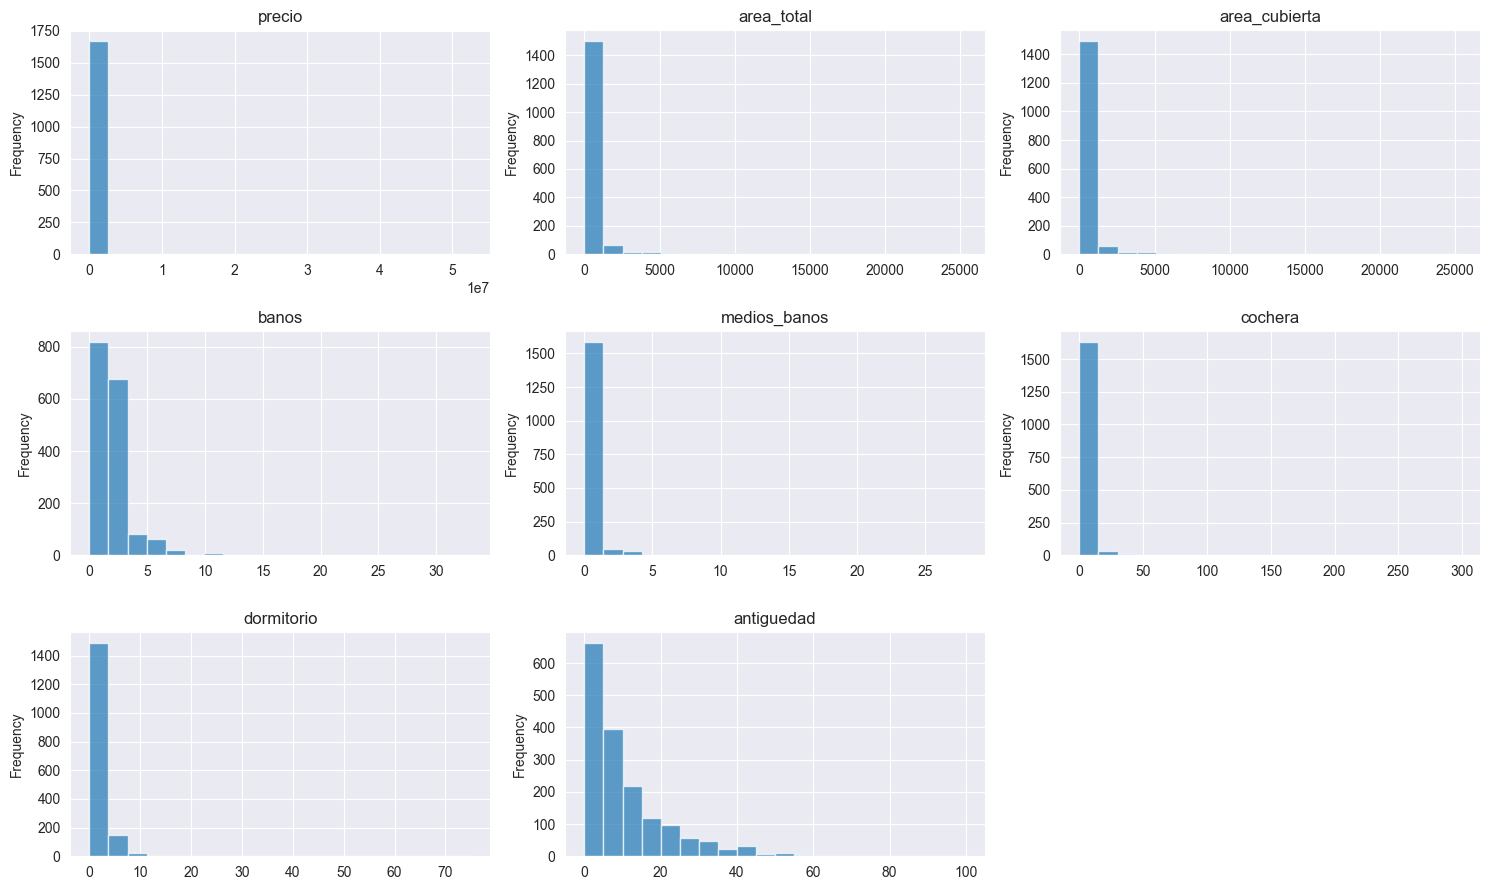

5️⃣  DIAGRAMAS DE CAJA
--------------------------------------------------------------------------------


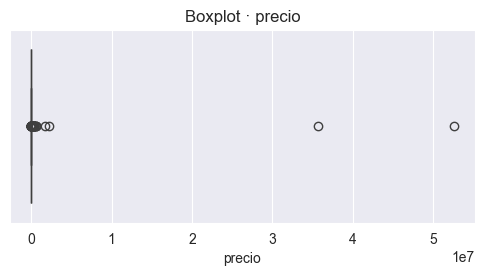

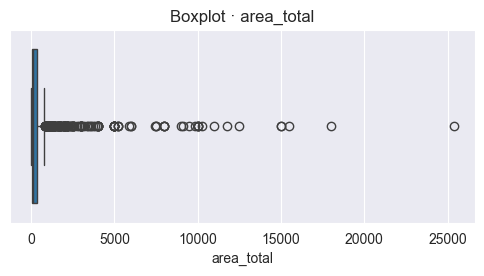

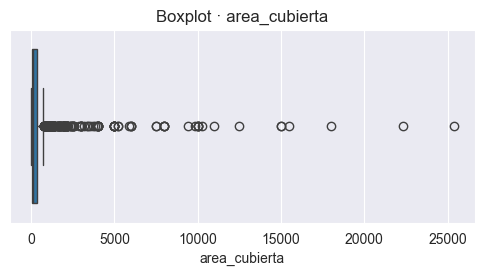

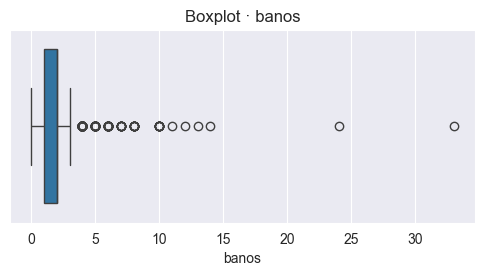

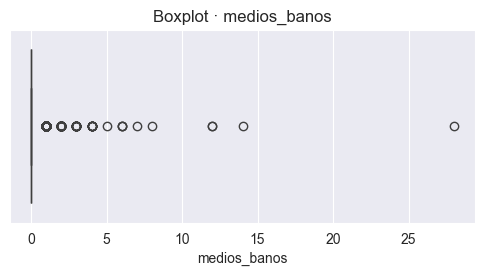

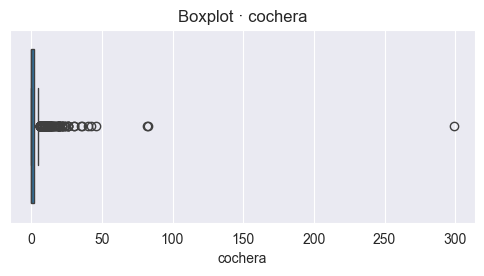

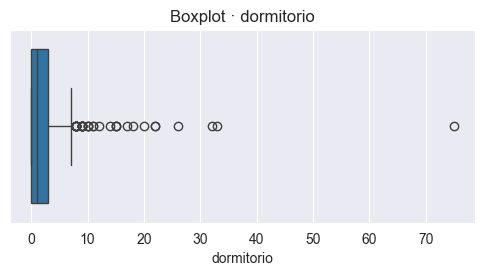

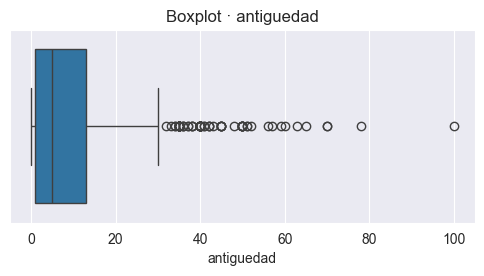

6️⃣  GRÁFICOS DE DISPERSIÓN
--------------------------------------------------------------------------------


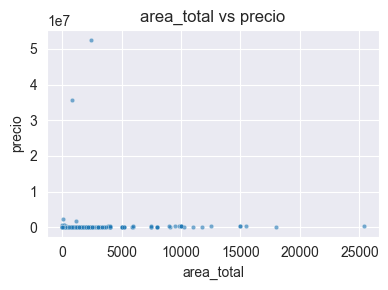

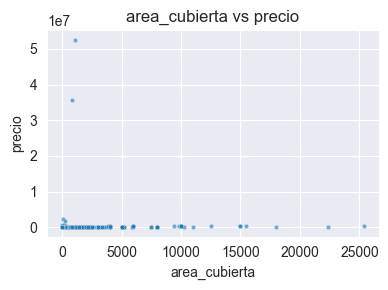

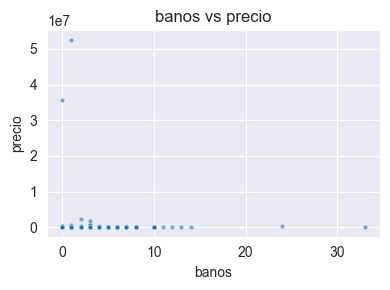

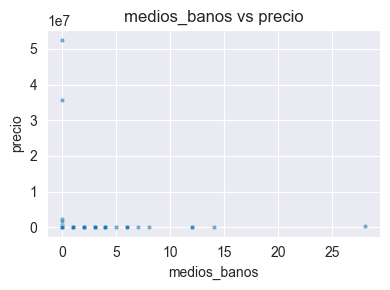

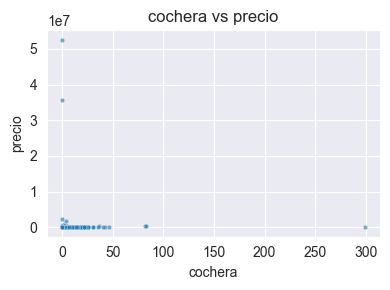

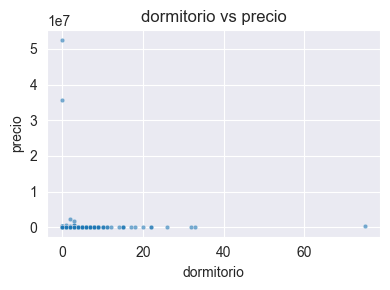

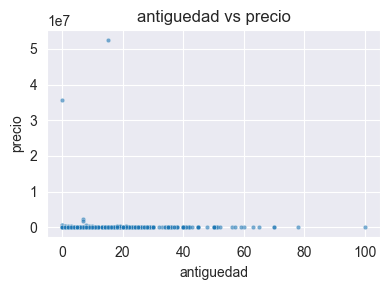


Exploración terminada ✔️


In [286]:
explorar_dataset(df,target='precio', max_pairplot=12)


=== Análisis para 'tipo_contrato' ===

Frecuencia absoluta (original):
tipo_contrato
Alquiler    1671
Venta          2
Name: count, dtype: int64

Frecuencia relativa (%) (original):
tipo_contrato
Alquiler    99.880454
Venta        0.119546
Name: proportion, dtype: float64


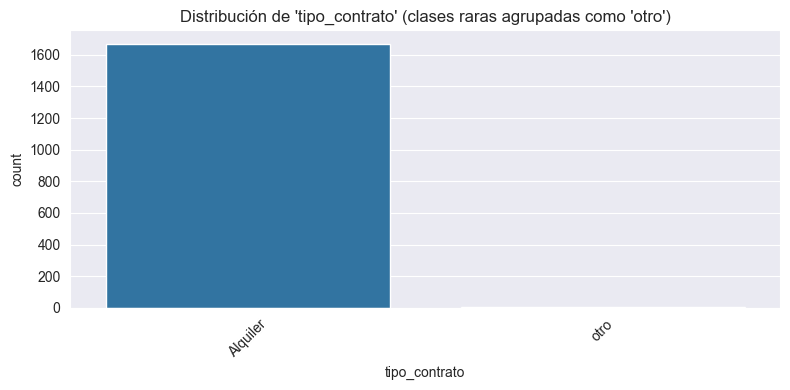


=== Análisis para 'tipo_vivienda' ===

Frecuencia absoluta (original):
tipo_vivienda
Departamento    698
Oficina         433
Local           409
Casa            101
Habitación       25
Garage            5
Hotel             2
Name: count, dtype: int64

Frecuencia relativa (%) (original):
tipo_vivienda
Departamento    41.721458
Oficina         25.881650
Local           24.447101
Casa             6.037059
Habitación       1.494322
Garage           0.298864
Hotel            0.119546
Name: proportion, dtype: float64


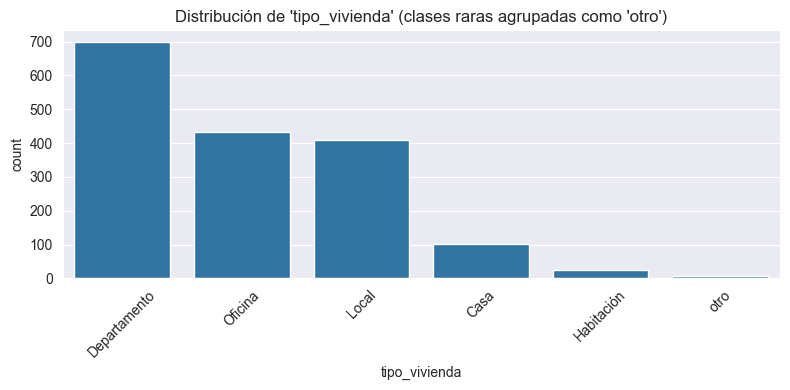


=== Análisis para 'distrito_original' ===

Frecuencia absoluta (original):
distrito_original
Lima                             1141
Santiago de Surco                  58
Miraflores                         46
Arequipa                           38
San Isidro                         36
La Molina                          32
Chorrillos                         21
La Victoria                        21
Lima Cercado                       18
San Borja                          18
Jesús María                        13
Callao                             13
Surquillo                          12
Ate Vitarte                        12
San Miguel                         10
Lince                              10
Cañete                             10
Comas                               9
San Juan de Miraflores              9
Punta Hermosa                       8
Chiclayo                            7
Trujillo                            7
Lurín                               7
Magdalena                       

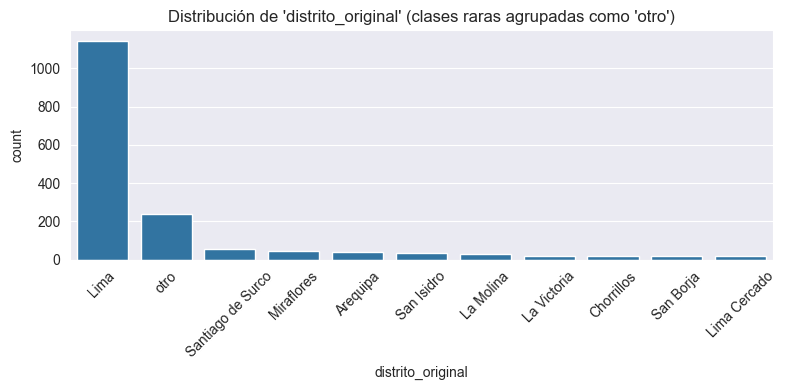


=== Análisis para 'direccion' ===

Frecuencia absoluta (original):
direccion
Parque Abtao,  San Isidro, Lima                                                                                                                                        13
Av. Pardo y Aliaga N° 699, Oficina 301, San Isidro,  San Isidro, Lima                                                                                                  10
Ave. Domingo Orue No 165, Surquillo, Piso 5 y 6, Lima, 15047,  San Fernando, Lima Cercado                                                                               8
Parque abtao,  San Isidro, Lima                                                                                                                                         8
Calle Dean Valdivia 148,  San Isidro, Lima                                                                                                                              8
Av. Circunvalacion Del Club Golf Los Incas Nro. 170 Int. Sr 403, 404 y 4

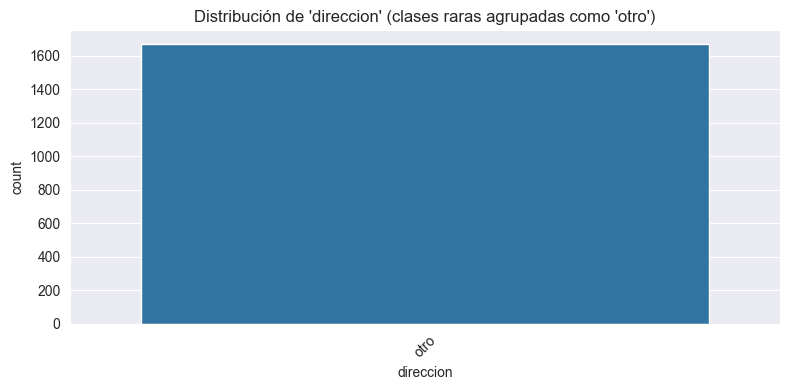


=== Análisis para 'descripcion' ===

Frecuencia absoluta (original):


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



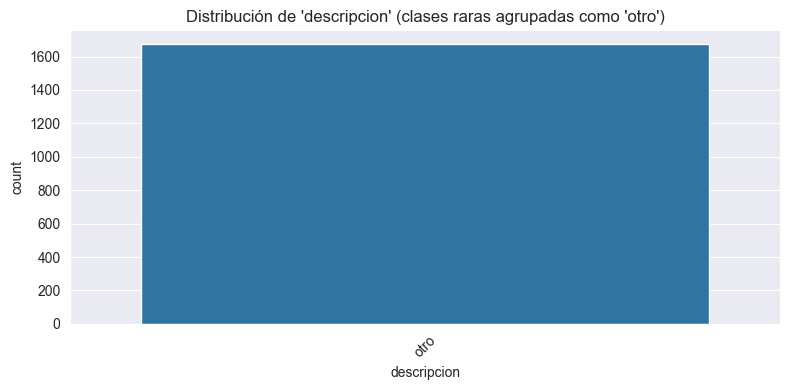


=== Análisis para 'url' ===

Frecuencia absoluta (original):
url
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-lince-lima-147856858                                                                 2
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-santiago-de-surco-lima-147849900                                                     2
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-santiago-de-surco-lima-147889280                                                     2
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-santiago-de-surco-lima-146743108                                                     2
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-lobaton-lince-5-a-mas-dormitorios-147787883                                          2
https://urbania.pe/inmueble/clasificado/alcllcin-alquiler-de-local-comercial-en-los-cedros-de-villa

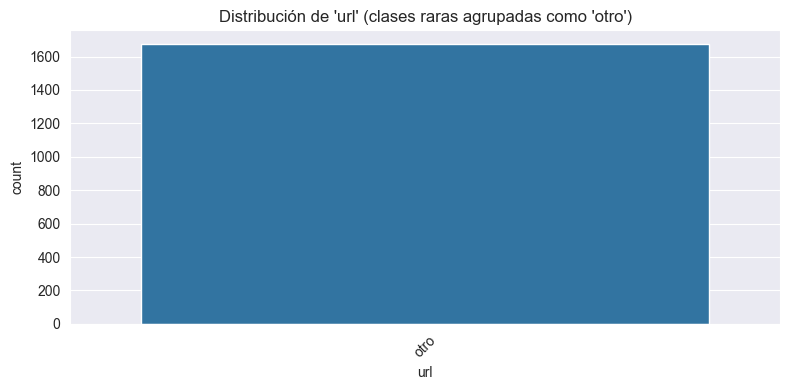


=== Análisis para 'fecha_extraccion' ===

Frecuencia absoluta (original):
fecha_extraccion
16/10/2025 19:59       5
16/10/2025 20:03       5
16/10/2025 20:02       4
16/10/2025 21:12       4
16/10/2025 21:13       4
16/10/2025 21:15       4
16/10/2025 21:17       4
16/10/2025 20:01       4
16/10/2025 20:00       4
16/10/2025 21:14       3
16/10/2025 19:58       2
16/10/2025 21:16       2
16/10/2025 21:18       2
06/11/2025 02:37:35    1
06/11/2025 02:37:49    1
06/11/2025 02:38:04    1
06/11/2025 02:38:18    1
06/11/2025 02:38:32    1
06/11/2025 02:39:15    1
06/11/2025 02:39:28    1
06/11/2025 02:39:41    1
06/11/2025 02:39:55    1
06/11/2025 02:40:08    1
16/10/2025 21:21:51    1
16/10/2025 21:22:05    1
16/10/2025 21:22:18    1
16/10/2025 21:22:32    1
16/10/2025 21:22:46    1
16/10/2025 21:23:29    1
16/10/2025 21:23:42    1
16/10/2025 21:23:57    1
16/10/2025 21:24:11    1
16/10/2025 21:24:25    1
16/10/2025 21:24:39    1
16/10/2025 21:24:54    1
16/10/2025 21:25:09    1
16/10/20

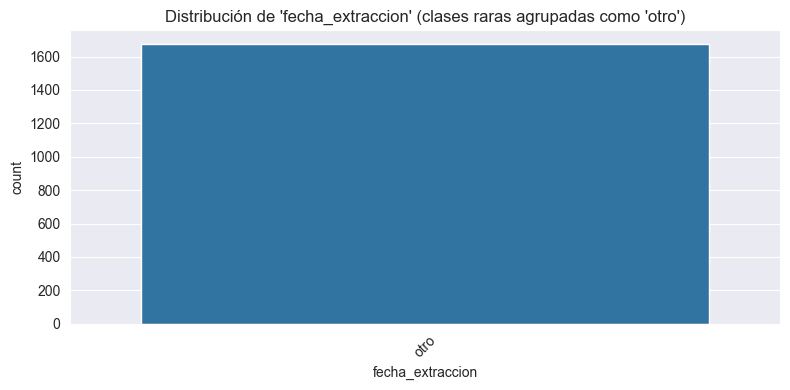


=== Análisis para 'departamento' ===

Frecuencia absoluta (original):
departamento
Lima           1537
Arequipa         46
Callao           14
Cajamarca        12
La libertad      11
Lambayeque        8
Ancash            7
Ica               7
Amazonas          6
Cusco             5
Piura             4
Loreto            4
Puno              2
San martin        2
Junin             1
Tumbes            1
Name: count, dtype: int64

Frecuencia relativa (%) (original):
departamento
Lima           92.201560
Arequipa        2.759448
Callao          0.839832
Cajamarca       0.719856
La libertad     0.659868
Lambayeque      0.479904
Ancash          0.419916
Ica             0.419916
Amazonas        0.359928
Cusco           0.299940
Piura           0.239952
Loreto          0.239952
Puno            0.119976
San martin      0.119976
Junin           0.059988
Tumbes          0.059988
Name: proportion, dtype: float64


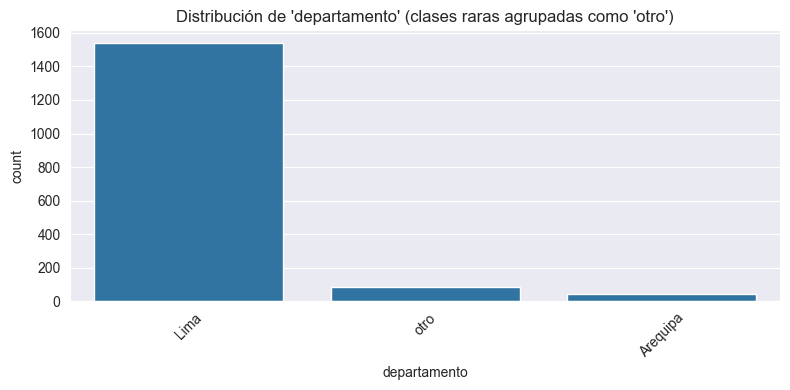


=== Análisis para 'provincia' ===

Frecuencia absoluta (original):
provincia
Lima                    1447
Arequipa                  35
Cañete                    18
Trujillo                  11
San miguel                10
Callao (prov.const.)       9
Chiclayo                   8
Huaral                     7
Chachapoyas                6
Huaylas                    6
Maynas                     4
Ica                        4
Cusco                      3
Barranca                   2
Bellavista                 2
Piura                      2
Chincha                    1
Huarochiri                 1
Calca                      1
Huaura                     1
Pisco                      1
Islay                      1
Urubamba                   1
Cajamarca                  1
Huaraz                     1
Huancayo                   1
Tumbes                     1
Sechura                    1
Name: count, dtype: int64

Frecuencia relativa (%) (original):
provincia
Lima                    91.235813
Are

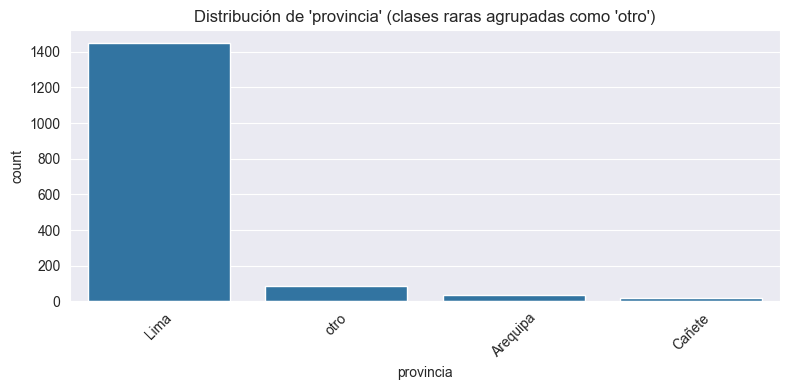


=== Análisis para 'distrito' ===

Frecuencia absoluta (original):
distrito
San isidro                       410
Miraflores                       149
Santiago de surco                124
Barranco                          74
Jesus maria                       73
San borja                         66
La molina                         51
Chorrillos                        50
Lince                             48
Surquillo                         42
Lurin                             39
La victoria                       37
Ate                               36
Lima cercado                      35
San miguel                        29
Comas                             26
Villa el salvador                 23
San martin de porres              17
San juan de miraflores            16
Punta hermosa                     14
Los olivos                        13
San juan de lurigancho            12
Cayma                             11
Asia                              10
Carabayllo                         8

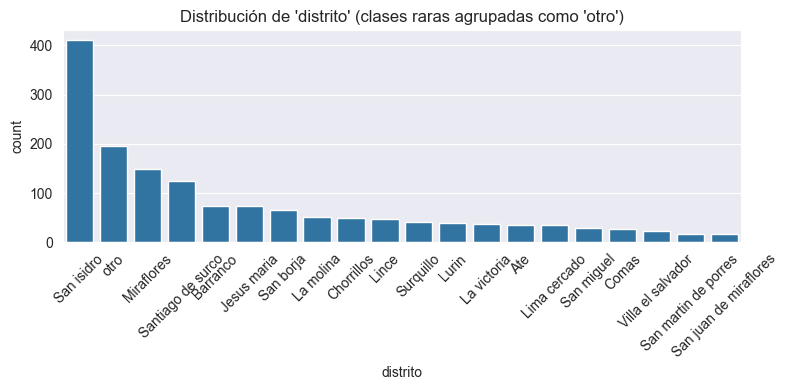


=== Análisis para 'otros' ===

Frecuencia absoluta (original):
otros
Parque Abtao                                                                                                                                  14
Cayma Top: Local Comercial DE 250 M² EN Esquina Sobre AV. Bolognesi — Ideal Para Marcas Líderes                                               10
Av. Pardo y Aliaga N° 699, Oficina 301, San Isidro                                                                                            10
Calle Dean Valdivia 148                                                                                                                        8
Parque abtao                                                                                                                                   8
Ave. Domingo Orue No 165, Surquillo, Piso 5 y 6, Lima, 15047, San Fernando                                                                     8
Av. Circunvalacion Del Club Golf Los Incas Nro. 170 Int. Sr 

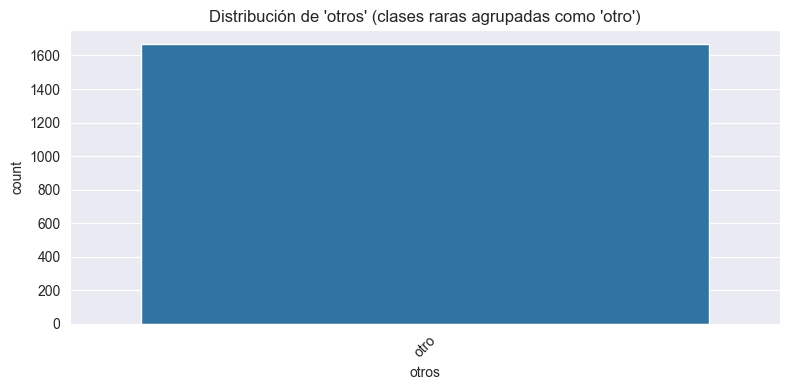

In [287]:
analizar_variables_categoricas(df)

# 3.Limpieza y estandarización de  datos

## 3.1 Limpieza

In [288]:
display(df.head())

,tipo_contrato,tipo_vivienda,precio,distrito_original,direccion,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,descripcion,url,fecha_extraccion,departamento,provincia,distrito,otros
0,Alquiler,Departamento,1200.0,Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",110.0,110.0,3,0,0,3,5,Alquiler Barato Departamento en Los Olivos\nAl...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Los olivos,"LOS CASTAÑOS 1317, 12 De Agosto"
1,Alquiler,Departamento,1300.0,Ate Vitarte,"De la Unión 303, 27 De Abril, Ate",60.0,60.0,1,0,0,1,5,Minidepartamento de un Dorm. en Tercer Piso / ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
2,Alquiler,Departamento,2650.0,Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate",160.0,160.0,1,1,0,3,5,"Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
3,Alquiler,Departamento,3850.0,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...",144.0,144.0,2,0,1,3,20,"Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, Al..."
4,Alquiler,Departamento,2850.0,Cayma,"Cayma Baja, Alto Gloria, Cayma",125.0,110.0,2,1,1,2,8,Departamento Alto de La Gloria - Cayma\nLindo ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Arequipa,Arequipa,Cayma,"Cayma Baja, Alto Gloria"


In [289]:
df=limpiar_dataset(df)



 Valores faltantes por variable independiente:
distrito_original      6
direccion              6
area_total            44
area_cubierta         63
departamento           6
provincia             87
distrito             133
otros                  7
dtype: int64


 Porcentaje de valores faltantes por variable independiente:
distrito_original    0.358637
direccion            0.358637
area_total           2.630006
area_cubierta        3.765690
departamento         0.358637
provincia            5.200239
distrito             7.949791
otros                0.418410
dtype: float64


In [290]:
display(df.head())
display(df.dtypes.sort_index())

,tipo_contrato,tipo_vivienda,precio,distrito_original,direccion,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,descripcion,url,fecha_extraccion,departamento,provincia,distrito,otros
0,Alquiler,Departamento,1200.0,Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",110.0,110.0,3,0,0,3,5,Alquiler Barato Departamento en Los Olivos\nAl...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Los olivos,"LOS CASTAÑOS 1317, 12 De Agosto"
1,Alquiler,Departamento,1300.0,Ate Vitarte,"De la Unión 303, 27 De Abril, Ate",60.0,60.0,1,0,0,1,5,Minidepartamento de un Dorm. en Tercer Piso / ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:58,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
2,Alquiler,Departamento,2650.0,Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate",160.0,160.0,1,1,0,3,5,"Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Ate,"De la Unión 303, 27 De Abril"
3,Alquiler,Departamento,3850.0,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...",144.0,144.0,2,0,1,3,20,"Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Lima,Lima,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, Al..."
4,Alquiler,Departamento,2850.0,Cayma,"Cayma Baja, Alto Gloria, Cayma",125.0,110.0,2,1,1,2,8,Departamento Alto de La Gloria - Cayma\nLindo ...,https://urbania.pe/inmueble/clasificado/alclap...,16/10/2025 19:59,Arequipa,Arequipa,Cayma,"Cayma Baja, Alto Gloria"


antiguedad             int64
area_cubierta        float64
area_total           float64
banos                  int64
cochera                int64
departamento          object
descripcion           object
direccion             object
distrito              object
distrito_original     object
dormitorio             int64
fecha_extraccion      object
medios_banos           int64
otros                 object
precio               float64
provincia             object
tipo_contrato         object
tipo_vivienda         object
url                   object
dtype: object

In [291]:
columnas_excluir = [
    "url",
    "distrito_original",
    "direccion",
    "descripcion",
    "fecha_extraccion",
    "otros"
]

df = pd.concat(
    [df[columnas_excluir], limpiar_vacios(df.drop(columns=columnas_excluir),binarias=[])],
    axis=1)

Variables binarias convertidas a número:  []
Imputación completada sin valores nulos restantes.


In [292]:
display(df.head())
display(df.dtypes.sort_index())

,url,distrito_original,direccion,descripcion,fecha_extraccion,otros,tipo_contrato,tipo_vivienda,precio,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,departamento,provincia,distrito
0,https://urbania.pe/inmueble/clasificado/alclap...,Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",Alquiler Barato Departamento en Los Olivos\nAl...,16/10/2025 19:58,"LOS CASTAÑOS 1317, 12 De Agosto",alquiler,departamento,1200.0,110.0,110.0,3,0,0,3,5,lima,lima,los olivos
1,https://urbania.pe/inmueble/clasificado/alclap...,Ate Vitarte,"De la Unión 303, 27 De Abril, Ate",Minidepartamento de un Dorm. en Tercer Piso / ...,16/10/2025 19:58,"De la Unión 303, 27 De Abril",alquiler,departamento,1300.0,60.0,60.0,1,0,0,1,5,lima,lima,ate
2,https://urbania.pe/inmueble/clasificado/alclap...,Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate","Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",16/10/2025 19:59,"De la Unión 303, 27 De Abril",alquiler,departamento,2650.0,160.0,160.0,1,1,0,3,5,lima,lima,ate
3,https://urbania.pe/inmueble/clasificado/alclap...,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...","Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",16/10/2025 19:59,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, Al...",alquiler,departamento,3850.0,144.0,144.0,2,0,1,3,20,lima,lima,miraflores
4,https://urbania.pe/inmueble/clasificado/alclap...,Cayma,"Cayma Baja, Alto Gloria, Cayma",Departamento Alto de La Gloria - Cayma\nLindo ...,16/10/2025 19:59,"Cayma Baja, Alto Gloria",alquiler,departamento,2850.0,125.0,110.0,2,1,1,2,8,arequipa,arequipa,cayma


antiguedad             int64
area_cubierta        float64
area_total           float64
banos                  int64
cochera                int64
departamento          object
descripcion           object
direccion             object
distrito              object
distrito_original     object
dormitorio             int64
fecha_extraccion      object
medios_banos           int64
otros                 object
precio               float64
provincia             object
tipo_contrato         object
tipo_vivienda         object
url                   object
dtype: object

In [293]:
df=limpiar_dataset(df)



 Valores faltantes por variable independiente:
distrito_original    6
direccion            6
otros                7
dtype: int64


 Porcentaje de valores faltantes por variable independiente:
distrito_original    0.358637
direccion            0.358637
otros                0.418410
dtype: float64


                         EXPLORACIÓN BÁSICA DEL DATASET                         

1️⃣  TIPOS DE DATOS
--------------------------------------------------------------------------------


,Nº columnas
object,11
int64,5
float64,3


antiguedad             int64
area_cubierta        float64
area_total           float64
banos                  int64
cochera                int64
departamento          object
descripcion           object
direccion             object
distrito              object
distrito_original     object
dormitorio             int64
fecha_extraccion      object
medios_banos           int64
otros                 object
precio               float64
provincia             object
tipo_contrato         object
tipo_vivienda         object
url                   object
dtype: object


2️⃣  VALORES NULOS POR COLUMNA
--------------------------------------------------------------------------------


,n_nulos
otros,7
distrito_original,6
direccion,6



3️⃣  ESTADÍSTICAS DESCRIPTIVAS
--------------------------------------------------------------------------------


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,1673,1667,https://urbania.pe/inmueble/clasificado/alcllc...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distrito_original,1667,70,Lima,1141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direccion,1667,1504,"Parque Abtao, San Isidro, Lima",13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
descripcion,1673,1652,Cayma Top: Local Comercial de 250 m² en Esquin...,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_extraccion,1673,1639,16/10/2025 19:59,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
otros,1666,1482,Parque Abtao,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_contrato,1673,2,alquiler,1671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_vivienda,1673,7,departamento,698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio,1673.0,NaN,NaN,NaN,72682.676031,1554003.803925,0.0,2250.0,4104.0,16461.0,52560000.0
area_total,1673.0,NaN,NaN,NaN,527.968918,1543.767011,1.0,65.0,135.0,356.0,25379.0



4️⃣  HISTOGRAMAS DE VARIABLES NUMÉRICAS
--------------------------------------------------------------------------------


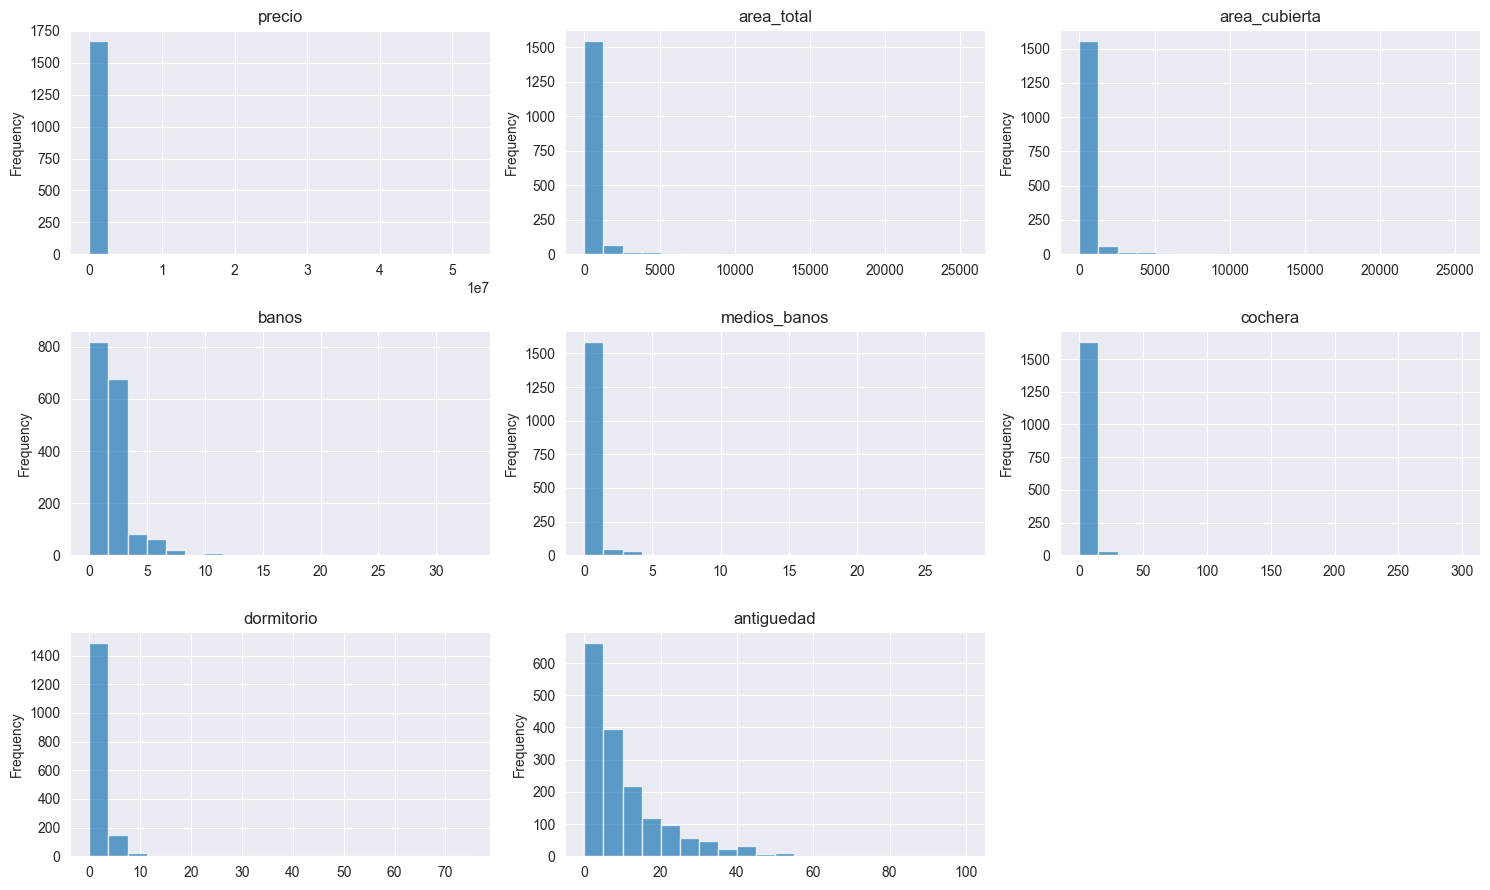

5️⃣  DIAGRAMAS DE CAJA
--------------------------------------------------------------------------------


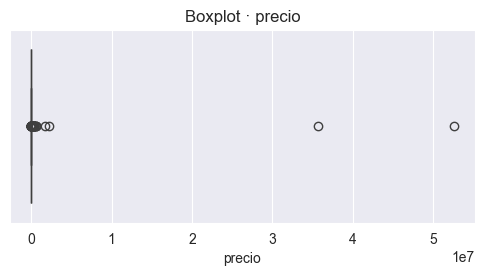

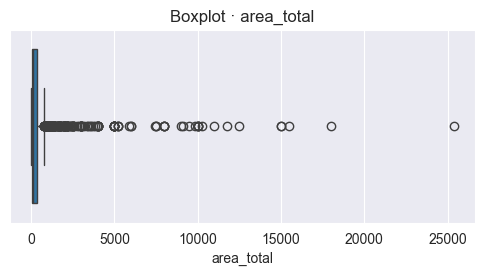

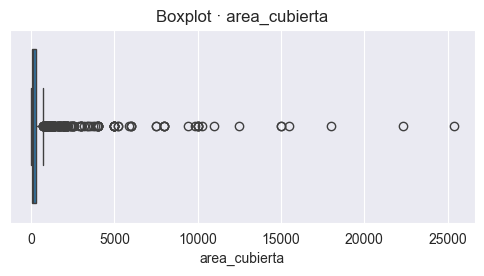

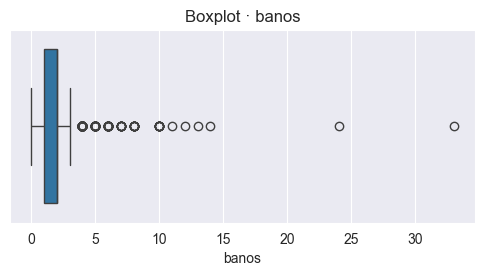

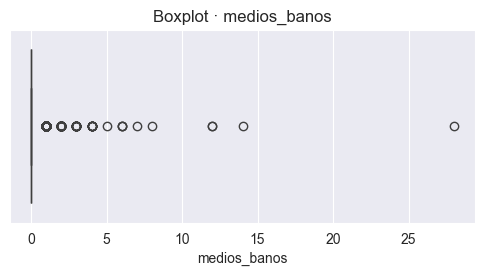

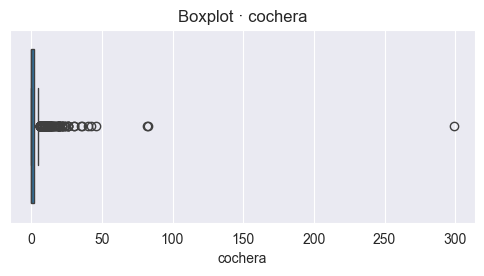

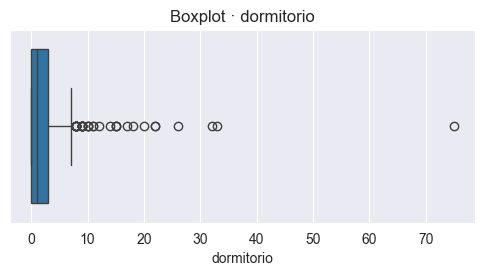

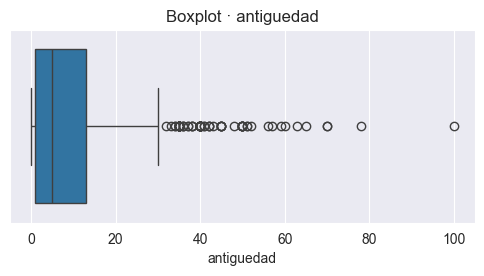

6️⃣  GRÁFICOS DE DISPERSIÓN
--------------------------------------------------------------------------------


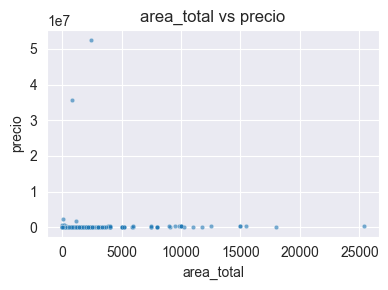

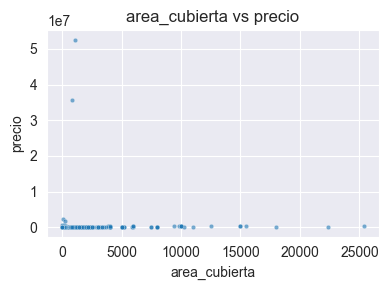

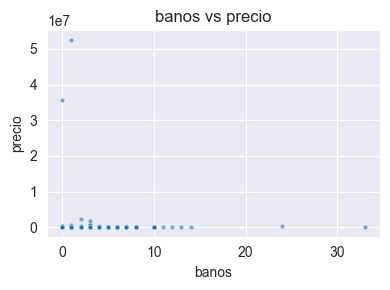

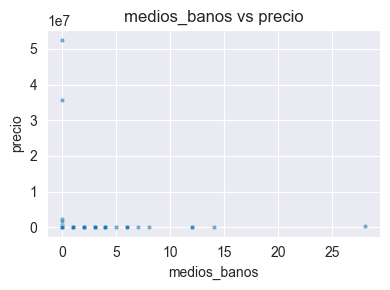

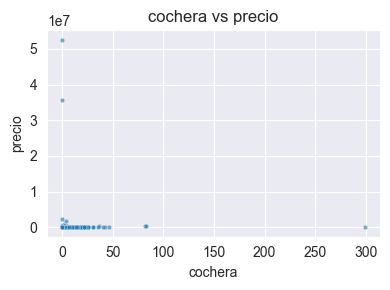

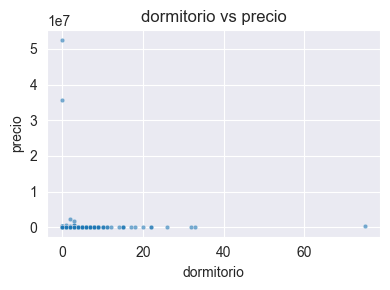

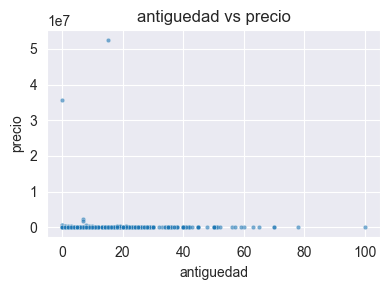


Exploración terminada ✔️


In [294]:
explorar_dataset(df,target='precio', max_pairplot=12)

## 3.2 Tratar outliers

Se explica algunas técnicas usasda:
**El método de Winsorización** reemplaza un percentil, por su valor percentil más cercado, por ejemplo:

Cualquier valor por debajo del percentil 1 se reemplaza por el valor exacto del percentil 1.Cualquier valor por encima del percentil 99 se reemplaza por el valor del percentil 99.

Se recomienda usar porque recorta valores extremos a percentiles y porque no se pierden registros y reduce el impacto de valores extremos.

**El método de conversión con Logarítmo** este método comprime valores grandes, preserva estructura y reduce asimetría. La forma en que se usa es aplica log(1 + x) a cada valor. Se recomienda ser utilizado especialmente en distribuaciones con asimetrías a la derecha o izquierda o en resumen porque reduce efecto de escalas grandes

**El método de capping** es establecer un valor máximo permitido. Este método  reduce la dispersión sin distorsionar la naturaleza de la variable

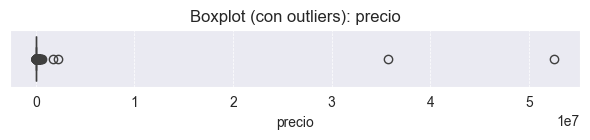

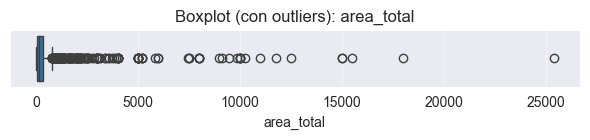

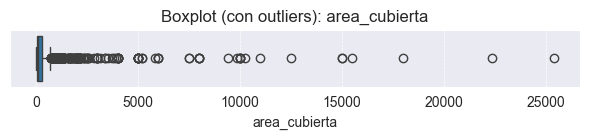

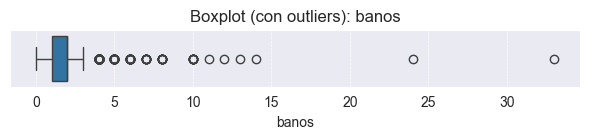

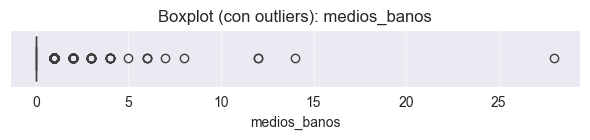

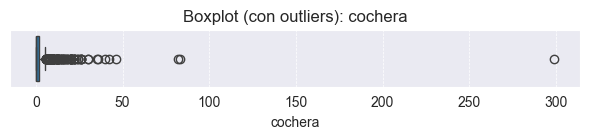

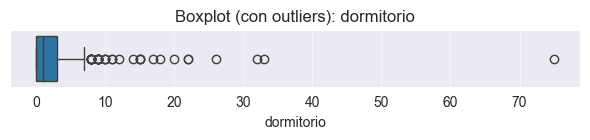

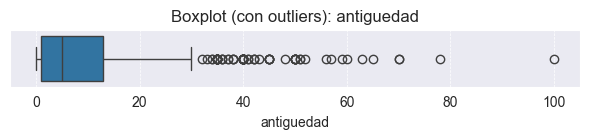

         Columna  Outliers detectados  Porcentaje
2  area_cubierta                  164        9.80
1     area_total                  153        9.15
5        cochera                  141        8.43
0         precio                  123        7.35
3          banos                   63        3.77
7     antiguedad                   61        3.65
4   medios_banos                   42        2.51
6     dormitorio                   38        2.27


In [295]:
df_numerico = df.select_dtypes(include=["number"])
outliers_dict, resumen_outliers = detectar_outliers_iqr_df(df_numerico)
print(resumen_outliers)

In [296]:
outliers_precio, low, high = outliers_por_columna(df, "precio")
outliers_precio

,url,distrito_original,direccion,descripcion,fecha_extraccion,otros,tipo_contrato,tipo_vivienda,precio,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,departamento,provincia,distrito
23,https://urbania.pe/inmueble/clasificado/alclap...,Cañete,"Mirador de Asia, Asia, Cañete",Vendo Lindo Departamento en El Mirador de Asia...,16/10/2025 20:03,Mirador de Asia,alquiler,departamento,548000.0,130.0,130.0,3,0,2,3,0,lima,cañete,asia
24,https://urbania.pe/inmueble/clasificado/alclap...,Cañete,"Mirador de Asia, Asia, Cañete",Vendo Lindo Departamento en El Mirador de Asia...,16/10/2025 20:04,Mirador de Asia,alquiler,departamento,548000.0,130.0,130.0,3,0,2,3,0,lima,cañete,asia
99,https://urbania.pe/inmueble/clasificado/alcllc...,Lima,"Av. manuel Olguin 211, Santiago de Surco, Lima",Local Comercial Manuel Olguín Frente Jockey Pl...,16/10/2025 21:51:22,Av. manuel Olguin 211,alquiler,local,63000.0,1041.0,1041.0,4,0,10,0,10,lima,lima,santiago de surco
144,https://urbania.pe/inmueble/clasificado/alclap...,Jesús María,"Av. Brasil 2477, Jesús María, Residencial San...",Alquiler de Departamento en Jesús María con Pi...,08/11/2025 14:37:54,"Av. Brasil 2477, Jesús María, Residencial San ...",alquiler,departamento,2250000.0,57.0,57.0,2,0,0,2,7,lima,lima,jesus maria
522,https://urbania.pe/inmueble/clasificado/alclca...,Cieneguilla,"Av nueva toledo, Cieneguilla, Cieneguilla",Alquiler de Linda Casa en Condominio Río del S...,08/11/2025 16:19:26,"Av nueva toledo, Cieneguilla",venta,casa,1695150.0,1127.0,242.0,3,0,4,3,7,lima,lima,cieneguilla
629,https://urbania.pe/inmueble/clasificado/alclha...,Chorrillos,"Andromeda 714, Ariosto Matellini, Chorrillos",Alquilo Habitación Semi Amoblada.\nAlquilo her...,08/11/2025 16:46:46,"Andromeda 714, Ariosto Matellini",alquiler,habitación,600650.0,16.0,16.0,1,0,1,1,8,lima,lima,chorrillos
637,https://urbania.pe/inmueble/clasificado/alclht...,Lima,"Av Javier Prado Este 5982, La Molina, Lima",Hotel en Alquiler – Javier Prado con La Molina...,08/11/2025 16:48:56,Av Javier Prado Este 5982,alquiler,hotel,58975.0,1353.0,1353.0,33,3,0,33,30,lima,lima,la molina
665,https://urbania.pe/inmueble/clasificado/alcllc...,Surquillo,"Gonzáles Prada 581, Lima, Barrio Medico, Surq...",Edificio Comercial 5 Pisos Límite Surquillo - ...,08/11/2025 16:53:23,"Gonzáles Prada 581, Lima, Barrio Medico",alquiler,local,65880.0,1441.0,300.0,10,0,9,0,10,lima,lima,surquillo
678,https://urbania.pe/inmueble/clasificado/alcllc...,Lima,"Av. Argentina 1932, Callao, Lima","Local Para Almacen o Taller, 9,856 m², Callao\...",08/11/2025 16:55:53,"Av. Argentina 1932, Callao",alquiler,local,238050.0,9856.0,9856.0,0,0,0,0,0,lima,none,none
692,https://urbania.pe/inmueble/clasificado/alcllc...,Arequipa,"Calle Mercaderes , Cercado, Arequipa",Se Alquila Local Comercial en Arequipa\nALQUIL...,08/11/2025 16:58:09,"Calle Mercaderes, Cercado",alquiler,local,66800.0,751.0,1802.0,4,0,0,0,12,arequipa,none,none


Como se aprecia en los anteriores pasos ya se realizo las siguietnes tareas:

- Ver registros duplicados
- Ver si existen registros vacios
- Reemplazar vacios
- Análisis de outliers

Ahora al estar completa y limpia

In [297]:
df.to_csv(
        "df_limpio.csv",
        mode="a",
        index=False,
        encoding="utf-8-sig",
        sep=";"
    )

In [298]:
display(df.head())
display(df.dtypes.sort_index())

,url,distrito_original,direccion,descripcion,fecha_extraccion,otros,tipo_contrato,tipo_vivienda,precio,area_total,area_cubierta,banos,medios_banos,cochera,dormitorio,antiguedad,departamento,provincia,distrito
0,https://urbania.pe/inmueble/clasificado/alclap...,Los Olivos,"LOS CASTAÑOS 1317, 12 De Agosto, Los Olivos",Alquiler Barato Departamento en Los Olivos\nAl...,16/10/2025 19:58,"LOS CASTAÑOS 1317, 12 De Agosto",alquiler,departamento,1200.0,110.0,110.0,3,0,0,3,5,lima,lima,los olivos
1,https://urbania.pe/inmueble/clasificado/alclap...,Ate Vitarte,"De la Unión 303, 27 De Abril, Ate",Minidepartamento de un Dorm. en Tercer Piso / ...,16/10/2025 19:58,"De la Unión 303, 27 De Abril",alquiler,departamento,1300.0,60.0,60.0,1,0,0,1,5,lima,lima,ate
2,https://urbania.pe/inmueble/clasificado/alclap...,Ate Vitarte,"De la Unión 303 , 27 De Abril, Ate","Triplex en Tercer, Cuarto y Quinto Piso / Ate ...",16/10/2025 19:59,"De la Unión 303, 27 De Abril",alquiler,departamento,2650.0,160.0,160.0,1,1,0,3,5,lima,lima,ate
3,https://urbania.pe/inmueble/clasificado/alclap...,Miraflores,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, A...","Alquilo Depa, Urb. Alexander Von Humboldt 2do ...",16/10/2025 19:59,"a 2 Cuadras del Óvalo de Higuereta, Piso 2, Al...",alquiler,departamento,3850.0,144.0,144.0,2,0,1,3,20,lima,lima,miraflores
4,https://urbania.pe/inmueble/clasificado/alclap...,Cayma,"Cayma Baja, Alto Gloria, Cayma",Departamento Alto de La Gloria - Cayma\nLindo ...,16/10/2025 19:59,"Cayma Baja, Alto Gloria",alquiler,departamento,2850.0,125.0,110.0,2,1,1,2,8,arequipa,arequipa,cayma


antiguedad             int64
area_cubierta        float64
area_total           float64
banos                  int64
cochera                int64
departamento          object
descripcion           object
direccion             object
distrito              object
distrito_original     object
dormitorio             int64
fecha_extraccion      object
medios_banos           int64
otros                 object
precio               float64
provincia             object
tipo_contrato         object
tipo_vivienda         object
url                   object
dtype: object